# World Model Pipeline

This notebook demonstrates the complete pipeline for the World Model, including:
1. **Data Loading**: How trajectories are loaded from local NPZ files or Hugging Face Hub.
2. **Architecture**: An overview of the modular world model components.
3. **Training**: A demonstration of the multi-step rollout loss calculation.
4. **Inference & MPC**: How the model is used for planning.

In [2]:
%load_ext autoreload
%autoreload 2
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Ensure project root is in path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '../..'))
sys.path.append(os.path.join(PROJECT_ROOT, 'src'))

from world_model.data import NPZEpisodeDataset, HFWindowDataset, collate_npz, collate_hf
from world_model.architecture import WorldModel
from world_model.engine.trainer import TrainConfig, rollout_loss
from world_model.mpc import cem_plan, CEMConfig

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using device: cuda


## 1. Data Loading

The world model can load data from two main sources:
- **Local NPZ Episodes**: Trajectories stored as individual `.npz` files.
- **Hugging Face Hub**: Trajectories hosted as Arrow/Parquet datasets.

### B. Hugging Face Dataloading

Loading lquan9/collect1...
[HFWindowDataset] Attempting to load from Hub: lquan9/collect1


HF Hub batch RGB shape: torch.Size([16, 50, 3, 224, 224])
Dimensions: Odom=13, IMU=10, Act=13


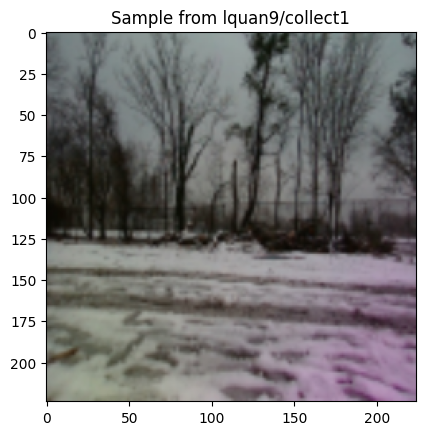

In [ ]:
hf_repo = "lquan9/collect1"
try:
    print(f"Loading {hf_repo}...")
    ds_hf = HFWindowDataset(hf_repo, img_size=224)
    
    dl_hf = DataLoader(
        ds_hf, 
        batch_size=16, 
        shuffle=True, 
        collate_fn=collate_hf,
        num_workers=4,
        pin_memory=True
    )
    
    batch = next(iter(dl_hf))
    print(f"HF Hub batch RGB shape: {batch.rgb.shape}")
    print(f"Dimensions: Odom={ds_hf.D_odom}, IMU={ds_hf.D_imu}, Act={ds_hf.D_act}")
    
    plt.imshow(batch.rgb[0, 0].permute(1, 2, 0).numpy())
    plt.title(f"Sample from {hf_repo}")
    plt.show()
except Exception as e:
    print(f"Could not load HF dataset {hf_repo}: {e}")

## 2. World Model Architecture

The `WorldModel` is modular, consisting of a vision encoder, a proprioception encoder, a fusion layer, and latent dynamics.

In [4]:
# Check if dataset was loaded to get correct dimensions
o_dim = ds_hf.D_odom if 'ds_hf' in locals() else 13 # Default for lquan9/collect1
i_dim = ds_hf.D_imu if 'ds_hf' in locals() else 10  # Default for lquan9/collect1
a_dim = ds_hf.D_act if 'ds_hf' in locals() else 13  # Default for lquan9/collect1

model = WorldModel(
    odom_dim=o_dim,
    imu_dim=i_dim,
    act_dim=a_dim, 
    backbone='cnn' 
).to(device)

print(model)

WorldModel(
  (vision): VisionEncoder(
    (net): Sequential(
      (0): Conv2d(4, 32, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
      (1): ReLU(inplace=True)
      (2): Conv2d(32, 64, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
      (3): ReLU(inplace=True)
      (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (5): ReLU(inplace=True)
      (6): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (proj): Linear(in_features=128, out_features=128, bias=True)
  )
  (proprio): ProprioEncoder(
    (net): Sequential(
      (0): Linear(in_features=23, out_features=256, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU(inplace=True)
      (4): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (fusion): Fusion(
    (net): Sequential(
      (0): Linear(in_features=256, out_features=256, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=256, out_feat

## 3. Training: Multi-step Rollout

During training, we roll out the latent dynamics for $H$ steps and compare the predicted latents and states with the actual ones.

In [5]:
if 'batch' in locals():
    cfg = TrainConfig(device=str(device), horizon=8)
    loss, logs = rollout_loss(model, batch, cfg)
    print(f"Total Loss: {loss.item():.4f}")
    for k, v in logs.items():
        if k != 'loss':
            print(f"  {k}: {v:.4f}")

Total Loss: 443.8347
  loss_z: 2.4801
  loss_state: 441.2209
  loss_risk: 0.6689


### B. Training Loop

In [6]:
import torch.optim as optim

def train_world_model(model, dataloader, epochs=5, lr=3e-4, device='cuda'):
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    cfg = TrainConfig(device=device, lr=lr)
    
    print(f"Starting training for {epochs} epochs on {device}...")
    
    for epoch in range(epochs):
        epoch_loss = 0
        batch_count = 0
        
        for batch in dataloader:
            optimizer.zero_grad()
            
            # Compute multi-step rollout loss
            loss, logs = rollout_loss(model, batch, cfg)
            
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            batch_count += 1
            
            if batch_count % 10 == 0:
                print(f"Epoch {epoch+1}, Batch {batch_count}, Loss: {loss.item():.4f}")
        
        avg_loss = epoch_loss / batch_count
        print(f"Epoch {epoch+1} Complete. Average Loss: {avg_loss:.4f}")

# train_world_model(model, dl_hf, epochs=2, device=str(device))

### C. Model Persistence (Save/Load)
Use these cells to save your progress or load a previously trained model, even after a kernel restart.

In [ ]:
def save_checkpoint(model, path="world_model_weights.pt"):
    torch.save(model.state_dict(), path)
    print(f"Model weights saved to {path}")

def load_checkpoint(model, path="world_model_weights.pt"):
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        model.eval()
        print(f"Model weights loaded from {path}")
    else:
        print(f"No checkpoint found at {path}")

# Save the current model state
save_checkpoint(model)

# Explicitly load from a previous checkpoint
load_checkpoint(model)

Model weights loaded from world_model_weights.pt


## 4. Inference & MPC Planning

We use the Cross-Entropy Method (CEM) to plan a sequence of actions that minimizes a cost function.

In [ ]:
def simple_cost_fn(state_seq, risk_seq, goal):
    # Cost = Distance to goal + risk penalty
    # state_seq[:, -1, :2] assumes first two dimensions are X, Y
    dist = torch.norm(state_seq[:, -1, :2] - goal[:, :2], dim=-1)
    risk_penalty = risk_seq.mean(dim=1) * 100.0
    return dist + risk_penalty

def run_inference(model, batch, device):
    # Ensure we are in eval mode
    model.eval()
    
    # Encode the initial state from the batch
    with torch.no_grad():
        z = model.encode(
            batch.rgb[0, 0:1].to(device), 
            batch.depth[0, 0:1].to(device), 
            batch.odom[0, 0:1].to(device), 
            batch.imu[0, 0:1].to(device)
        )
        z0 = z.z

    goal = torch.tensor([[5.0, 5.0]], device=device)
    cem_cfg = CEMConfig(horizon=15, iters=5, population=100, action_dim=a_dim)

    best_action, best_seq = cem_plan(model, z0, goal, simple_cost_fn, cem_cfg, device)

    print(f"Best initial action: {best_action.cpu().numpy()}")
    print(f"Planned sequence shape: {best_seq.shape}")

if 'batch' in locals():
    # Load best weights before inference if needed
    # load_checkpoint(model)
    run_inference(model, batch, device)
else:
    print("Please load a data batch in Section 1 to run inference.")